In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
!ls -l

total 3584
drwxr-xr-x 1 root root    4096 Sep  4 13:32 sample_data
-rw-r--r-- 1 root root  646800 Sep 29 04:03 test.csv
-rw-r--r-- 1 root root 3015158 Sep 29 04:03 train.csv


In [ ]:
!cp /val.csv .
!cp /train.csv .

# Trainning & Validation Dataset Mentah

--> Device Komputasi: cuda (Tesla T4)
Data Siap: Train=9,993 baris | Val=2,141 baris


config.json:   0%|          | 0.00/1.53k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/229k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]


🚀 RUNNING EKSPERIMEN: LOSS = FOCAL | EPOCHS = 4


... (2 outputs left out)

model.safetensors: reconstructing file:   0%|          |  0.00B /  498MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Epoch 1/4 [134.0s] | Train Loss: 0.0544 | Val Loss: 0.0140 | Val Acc: 98.79% | Val F1: 98.79%
  --> Checkpoint model terbaik disimpan: best_model_focal.pt (Val F1: 98.79%)
Epoch 2/4 [131.1s] | Train Loss: 0.0080 | Val Loss: 0.0117 | Val Acc: 99.44% | Val F1: 99.44%
  --> Checkpoint model terbaik disimpan: best_model_focal.pt (Val F1: 99.44%)
Epoch 3/4 [131.6s] | Train Loss: 0.0042 | Val Loss: 0.0121 | Val Acc: 99.21% | Val F1: 99.21%
Epoch 4/4 [131.3s] | Train Loss: 0.0024 | Val Loss: 0.0097 | Val Acc: 99.53% | Val F1: 99.53%
  --> Checkpoint model terbaik disimpan: best_model_focal.pt (Val F1: 99.53%)


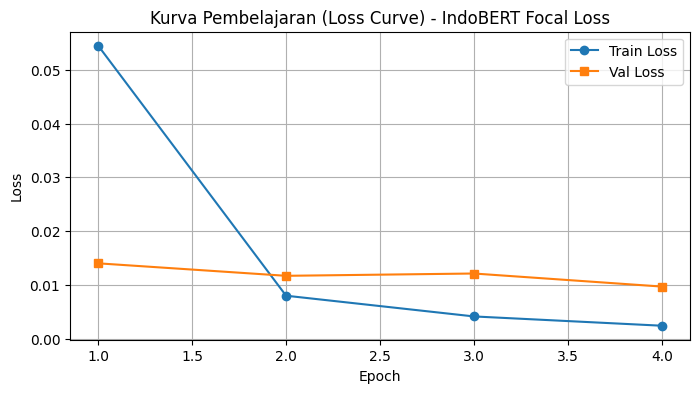


🏆 MODEL UTAMA SELESAI! File tersimpan: best_model_focal.pt
Waktu total aktual: 528.0 detik (~8.8 menit)


In [ ]:
# =============================================================================
# INSPECT-AI: FASE 3 - PELATIHAN INDOBERT & ABLASI LOSS DI GOOGLE COLAB
# =============================================================================

!pip install -q transformers accelerate scikit-learn matplotlib

import os
import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.optim import AdamW
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModel, get_linear_schedule_with_warmup
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score

# -----------------------------------------------------------------------------
# 1. SET SEED UNTUK REPRODUSIBILITAS ILMIAH
# -----------------------------------------------------------------------------
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"--> Device Komputasi: {device} ({torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'No GPU'})")

# -----------------------------------------------------------------------------
# 2. DEFINISI LOSS (FOCAL LOSS vs CROSS-ENTROPY)
# -----------------------------------------------------------------------------
class FocalLoss(nn.Module):
    def __init__(self, gamma=2.0):
        super(FocalLoss, self).__init__()
        self.gamma = gamma

    def forward(self, logits, targets):
        ce_loss = F.cross_entropy(logits, targets, reduction='none')
        pt = torch.exp(-ce_loss)
        focal_loss = ((1.0 - pt) ** self.gamma) * ce_loss
        return focal_loss.mean()

# -----------------------------------------------------------------------------
# 3. ARSITEKTUR INDOBERT DENGAN FREEZE EMBEDDING & LAYER 0-7
# -----------------------------------------------------------------------------
class IndoBERTHoaxClassifier(nn.Module):
    def __init__(self, model_name="indobenchmark/indobert-base-p1", num_classes=2, dropout_rate=0.3):
        super(IndoBERTHoaxClassifier, self).__init__()
        self.indobert = AutoModel.from_pretrained(model_name)

        # Bekukan Embeddings & Layer 0-7 (Sesuai Desain Azis et al.)
        for param in self.indobert.embeddings.parameters():
            param.requires_grad = False
        for i in range(8):
            for param in self.indobert.encoder.layer[i].parameters():
                param.requires_grad = False

        self.dropout = nn.Dropout(p=dropout_rate)
        self.classifier = nn.Linear(self.indobert.config.hidden_size, num_classes)

    def forward(self, input_ids, attention_mask):
        outputs = self.indobert(input_ids=input_ids, attention_mask=attention_mask)
        cls_rep = outputs.last_hidden_state[:, 0, :]
        return self.classifier(self.dropout(cls_rep))

# -----------------------------------------------------------------------------
# 4. DATASET & DATALOADER
# -----------------------------------------------------------------------------
class NewsDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_len=128):
        self.texts = texts
        self.labels = labels
        self.tokenizer = tokenizer
        self.max_len = max_len

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, item):
        encoding = self.tokenizer(
            str(self.texts[item]),
            add_special_tokens=True,
            max_length=self.max_len,
            padding='max_length',
            truncation=True,
            return_attention_mask=True,
            return_tensors='pt'
        )
        return {
            'input_ids': encoding['input_ids'].flatten(),
            'attention_mask': encoding['attention_mask'].flatten(),
            'labels': torch.tensor(self.labels[item], dtype=torch.long)
        }

# Muat data
train_df = pd.read_csv("train.csv")
val_df = pd.read_csv("val.csv")

print(f"Data Siap: Train={len(train_df):,} baris | Val={len(val_df):,} baris")

MODEL_NAME = "indobenchmark/indobert-base-p1"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
MAX_LEN = 128  # Berdasarkan bukti empiris p99 = 118 token
BATCH_SIZE = 32

train_loader = DataLoader(NewsDataset(train_df['text'].values, train_df['label'].values, tokenizer, MAX_LEN), batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(NewsDataset(val_df['text'].values, val_df['label'].values, tokenizer, MAX_LEN), batch_size=BATCH_SIZE, shuffle=False)

# -----------------------------------------------------------------------------
# 5. FUNGSI TRAINING MANDIRI
# -----------------------------------------------------------------------------
def train_experiment(loss_type="focal", epochs=4, lr=2e-5, save_name="best_model.pt"):
    set_seed(42)
    print("\n" + "=" * 70)
    print(f"🚀 RUNNING EKSPERIMEN: LOSS = {loss_type.upper()} | EPOCHS = {epochs}")
    print("=" * 70)

    model = IndoBERTHoaxClassifier(MODEL_NAME).to(device)
    criterion = FocalLoss(gamma=2.0) if loss_type == "focal" else nn.CrossEntropyLoss()

    trainable_params = [p for p in model.parameters() if p.requires_grad]
    optimizer = AdamW(trainable_params, lr=lr, weight_decay=0.01)

    total_steps = len(train_loader) * epochs
    scheduler = get_linear_schedule_with_warmup(optimizer, num_warmup_steps=int(total_steps * 0.1), num_training_steps=total_steps)

    best_val_f1 = 0.0
    history = []

    for epoch in range(epochs):
        t0 = time.time()
        model.train()
        train_loss = 0

        for batch in train_loader:
            input_ids = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            labels = batch['labels'].to(device)

            optimizer.zero_grad()
            logits = model(input_ids, attention_mask)
            loss = criterion(logits, labels)
            loss.backward()
            nn.utils.clip_grad_norm_(trainable_params, max_norm=1.0)
            optimizer.step()
            scheduler.step()
            train_loss += loss.item()

        avg_train_loss = train_loss / len(train_loader)

        # Evaluasi Validasi
        model.eval()
        val_loss, val_preds, val_targets = 0, [], []

        with torch.no_grad():
            for batch in val_loader:
                input_ids = batch['input_ids'].to(device)
                attention_mask = batch['attention_mask'].to(device)
                labels = batch['labels'].to(device)

                logits = model(input_ids, attention_mask)
                loss = criterion(logits, labels)
                val_loss += loss.item()

                preds = torch.argmax(logits, dim=1).cpu().numpy()
                val_preds.extend(preds)
                val_targets.extend(labels.cpu().numpy())

        avg_val_loss = val_loss / len(val_loader)
        acc = accuracy_score(val_targets, val_preds)
        f1 = f1_score(val_targets, val_preds, average='macro')
        dur = time.time() - t0

        print(f"Epoch {epoch+1}/{epochs} [{dur:.1f}s] | Train Loss: {avg_train_loss:.4f} | Val Loss: {avg_val_loss:.4f} | Val Acc: {acc*100:.2f}% | Val F1: {f1*100:.2f}%")

        history.append({'epoch': epoch+1, 'train_loss': avg_train_loss, 'val_loss': avg_val_loss, 'val_acc': acc, 'val_f1': f1, 'duration': dur})

        if f1 > best_val_f1:
            best_val_f1 = f1
            torch.save(model.state_dict(), save_name)
            print(f"  --> Checkpoint model terbaik disimpan: {save_name} (Val F1: {best_val_f1*100:.2f}%)")

    return pd.DataFrame(history), best_val_f1

# -----------------------------------------------------------------------------
# 6. EKSEKUSI TRAINING MODEL UTAMA (FOCAL LOSS)
# -----------------------------------------------------------------------------
history_focal, best_f1_focal = train_experiment(loss_type="focal", epochs=4, lr=2e-5, save_name="best_model_focal.pt")

# Plot Kurva Loss untuk Pemantauan Overfitting (Bahan Skripsi Bab 4)
plt.figure(figsize=(8, 4))
plt.plot(history_focal['epoch'], history_focal['train_loss'], label='Train Loss', marker='o')
plt.plot(history_focal['epoch'], history_focal['val_loss'], label='Val Loss', marker='s')
plt.title('Kurva Pembelajaran (Loss Curve) - IndoBERT Focal Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.savefig("loss_curve_focal.png", dpi=300)
plt.show()

print("\n" + "=" * 70)
print(f"🏆 MODEL UTAMA SELESAI! File tersimpan: best_model_focal.pt")
print(f"Waktu total aktual: {history_focal['duration'].sum():.1f} detik (~{history_focal['duration'].sum()/60:.1f} menit)")
print("=" * 70)

# Kode Evaluasi Independen & Tabel Pembuktian Sub-Topik

In [ ]:
import pandas as pd
import numpy as np
import torch
from torch.utils.data import DataLoader
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score

# 1. LOAD TEST SET INDEPENDEN (2.142 BARIS)
test_df = pd.read_csv("test.csv")
print("=" * 75)
print(f"🔬 EVALUASI RESMI TEST SET (TOTAL: {len(test_df):,} BARIS INDEPENDEN)")
print("=" * 75)

# Pastikan kolom sub_topic dan label ada
assert 'sub_topic' in test_df.columns, "Kolom sub_topic tidak ditemukan di test.csv!"
assert 'label' in test_df.columns, "Kolom label tidak ditemukan di test.csv!"

test_loader = DataLoader(
    NewsDataset(test_df['text'].values, test_df['label'].values, tokenizer, max_len=128),
    batch_size=32,
    shuffle=False
)

# 2. MUAT MODEL TERBAIK HASIL TRAINING TADI
eval_model = IndoBERTHoaxClassifier(MODEL_NAME).to(device)
eval_model.load_state_dict(torch.load("best_model_focal.pt"))
eval_model.eval()

test_preds = []
test_probs = []

print("--> Menjalankan inferensi pada seluruh 2.142 naskah data uji...")
with torch.no_grad():
    for batch in test_loader:
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)

        logits = eval_model(input_ids, attention_mask)
        probs = torch.softmax(logits, dim=1)[:, 1] # Probabilitas kelas Hoaks
        preds = torch.argmax(logits, dim=1)

        test_preds.extend(preds.cpu().numpy())
        test_probs.extend(probs.cpu().numpy())

test_df['pred'] = test_preds
test_df['prob_hoax'] = test_probs
test_df['is_correct'] = (test_df['pred'] == test_df['label']).astype(int)

# -----------------------------------------------------------------------------
# 3. METRIK EVALUASI KESELURUHAN (BAHAN BAB 4)
# -----------------------------------------------------------------------------
acc_global = accuracy_score(test_df['label'], test_df['pred'])
f1_global = f1_score(test_df['label'], test_df['pred'], average='macro')
cm = confusion_matrix(test_df['label'], test_df['pred'])

print("\n" + "=" * 75)
print("📊 [1] KINERJA GLOBAL MODEL INDOBERT PADA DATA UJI (test.csv):")
print("=" * 75)
print(f"• Akurasi Keseluruhan : {acc_global * 100:.2f}%")
print(f"• Macro F1-Score      : {f1_global * 100:.2f}%")

print("\nConfusion Matrix (Matriks Konfusi):")
print(f"  [ TN: {cm[0][0]:<5} | FP: {cm[0][1]:<5} ]  --> Fakta Benar vs Salah Tuduh")
print(f"  [ FN: {cm[1][0]:<5} | TP: {cm[1][1]:<5} ]  --> Hoaks Lolos vs Hoaks Tertangkap")

print("\nLaporan Klasifikasi Lengkap:")
print(classification_report(test_df['label'], test_df['pred'], target_names=["Fakta (0)", "Hoaks (1)"], digits=4))

# -----------------------------------------------------------------------------
# 4. TABEL PEMBUKTIAN SUB-TOPIK: APAKAH INDOBERT MENGALAHKAN SHORTCUT TF-IDF?
# -----------------------------------------------------------------------------
print("\n" + "=" * 75)
print("🔍 [2] TABEL UJI SUB-TOPIK: MEMBUKTIKAN INDOBERT BUKAN SHORTCUT TOPIK")
print("=" * 75)

sub_summary = test_df.groupby(['sub_topic', 'label'])['is_correct'].agg(
    Akurasi_IndoBERT='mean',
    Jumlah_Sampel='size',
    Benar='sum'
).reset_index()

# Tambahkan kolom pembanding baseline TF-IDF yang kemarin
tfidf_benchmarks = {
    ('hukum', 0): 0.588, ('hukum', 1): 0.976,
    ('kebijakan', 0): 0.842, ('kebijakan', 1): 0.970,
    ('pemilu', 0): 0.972, ('pemilu', 1): 0.780,
    ('tokoh', 0): 0.845, ('tokoh', 1): 0.974
}

sub_summary['Baseline_TFIDF'] = sub_summary.apply(lambda r: tfidf_benchmarks.get((r['sub_topic'], r['label']), np.nan), axis=1)
sub_summary['Kenaikan_(Delta)'] = (sub_summary['Akurasi_IndoBERT'] - sub_summary['Baseline_TFIDF']) * 100

sub_summary['Akurasi_IndoBERT'] = (sub_summary['Akurasi_IndoBERT'] * 100).round(2).astype(str) + "%"
sub_summary['Baseline_TFIDF'] = (sub_summary['Baseline_TFIDF'] * 100).round(2).astype(str) + "%"
sub_summary['Kenaikan_(Delta)'] = sub_summary['Kenaikan_(Delta)'].apply(lambda x: f"+{x:.2f}%" if x > 0 else f"{x:.2f}%")
sub_summary['label'] = sub_summary['label'].map({0: "Fakta (0)", 1: "Hoaks (1)"})

print(sub_summary.to_string(index=False))

# -----------------------------------------------------------------------------
# 5. TABEL PERBANDINGAN TIGA MODEL UNTUK BAB 4 SKRIPSI
# -----------------------------------------------------------------------------
print("\n" + "=" * 75)
print("🏆 [3] TABEL RESMI PERBANDINGAN TIGA METODE (BAHAN BAB 4):")
print("=" * 75)
comp_table = pd.DataFrame([
    {"Metode / Model": "1. Heuristik Topik Saja", "Akurasi": "78.80%", "Keterangan": "Shortcut prior topik murni"},
    {"Metode / Model": "2. Baseline Linear TF-IDF + LR", "Akurasi": "93.79%", "Keterangan": "Model kata kunci tradisional (Bag of Words)"},
    {"Metode / Model": "3. IndoBERT Base P1 + Focal Loss", "Akurasi": f"{acc_global*100:.2f}%", "Keterangan": "Deep Learning Bidirectional Transformer"}
])
print(comp_table.to_string(index=False))
print("=" * 75)

🔬 EVALUASI RESMI TEST SET (TOTAL: 2,142 BARIS INDEPENDEN)


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

--> Menjalankan inferensi pada seluruh 2.142 naskah data uji...

📊 [1] KINERJA GLOBAL MODEL INDOBERT PADA DATA UJI (test.csv):
• Akurasi Keseluruhan : 99.35%
• Macro F1-Score      : 99.35%

Confusion Matrix (Matriks Konfusi):
  [ TN: 1068  | FP: 3     ]  --> Fakta Benar vs Salah Tuduh
  [ FN: 11    | TP: 1060  ]  --> Hoaks Lolos vs Hoaks Tertangkap

Laporan Klasifikasi Lengkap:
              precision    recall  f1-score   support

   Fakta (0)     0.9898    0.9972    0.9935      1071
   Hoaks (1)     0.9972    0.9897    0.9934      1071

    accuracy                         0.9935      2142
   macro avg     0.9935    0.9935    0.9935      2142
weighted avg     0.9935    0.9935    0.9935      2142


🔍 [2] TABEL UJI SUB-TOPIK: MEMBUKTIKAN INDOBERT BUKAN SHORTCUT TOPIK
sub_topic     label Akurasi_IndoBERT  Jumlah_Sampel  Benar Baseline_TFIDF Kenaikan_(Delta)
    hukum Fakta (0)           100.0%             17     17          58.8%          +41.20%
    hukum Hoaks (1)           100.0%    

# Analisis 14 Naskah yang Salah (Bahan Analisis Bab 4

In [ ]:
# Intip 14 naskah yang salah diklarifikasi
errors = test_df[test_df['is_correct'] == 0]
print(f"Total Naskah yang Salah Ditebak: {len(errors)} baris\n")

for idx, (_, r) in enumerate(errors.head(5).iterrows(), 1):
    tipe_salah = "False Negative (Hoaks lolos)" if r['label'] == 1 else "False Positive (Fakta salah tuduh)"
    print(f"{idx}. [{tipe_salah} | Topik: {r['sub_topic'].upper()} | Probabilitas Hoaks: {r['prob_hoax']:.3f}]:")
    print(f"   \"{r['text'][:180]}...\"\n")

Total Naskah yang Salah Ditebak: 14 baris

1. [False Negative (Hoaks lolos) | Topik: TOKOH | Probabilitas Hoaks: 0.039]:
   "Jokowi Berharap, Kita Semua Dapat Menerima Kehadiran TKA Cina sebagai Saudara Yang Mencari Nafkah Disini . Jokowi Berharap, Kita Semuua Dapat Menerima Kehadiran TKA Cina sebagai Sa..."

2. [False Positive (Fakta salah tuduh) | Topik: PEMILU | Probabilitas Hoaks: 0.520]:
   "Bukan dengan Pasukan Militer, Senjata Ini Akan Digunakan Biden untuk Lawan China. Bukan dengan Pasukan Militer, Senjata Ini Akan Digunakan Biden untuk Lawan China Presiden Amerika ..."

3. [False Negative (Hoaks lolos) | Topik: PEMILU | Probabilitas Hoaks: 0.428]:
   "Lawan Gus Ipul, Gerinda Usung Ahmad Dhani di Pilwali Pasuruan . Ahmad Dhani dan elite Partai Gerindra Sufmi Dasco Ahmad membantah klaim yang menyebutkan Ahmad Dhani maju Pilkada Pa..."

4. [False Negative (Hoaks lolos) | Topik: TOKOH | Probabilitas Hoaks: 0.342]:
   "Draf Revisi UU Ketenagakerjaan Hapus Cuti Haid. Menteri Ketenag